# Movimento de passageiros no município do Rio de Janeiro, 1995–2025

Giovanna Sigette Lobo e Theo Cubas Reis · Orientação de Alexandre Neves Louzada  
Centro Universitário La Salle do Rio de Janeiro (UniLaSalle-RJ) · Sistemas de Informação · 6º período · 2026.2  
Linguagem de Programação (Análise e Visualização de Dados com Python)

Como mudou o peso dos ônibus no movimento de passageiros do Rio de Janeiro e quais modais recuperaram o volume registrado em 2019? O estudo usa a Tabela 440 do Data.Rio para acompanhar seis séries anuais entre 1995 e 2025. A planilha original foi tratada em Python, mantendo a unidade de milhares de passageiros e as lacunas documentadas para o bonde de Santa Teresa. A comparação combina volumes absolutos, participações em anos com cobertura completa e índices relativos a 2019. Os ônibus mantiveram o maior movimento ao longo da série, mas sua participação caiu de 84,7% em 1995 para 68,1% em 2025. No mesmo intervalo, o metrô passou de 6,0% para 18,9%. Em 2020, todos os modais registraram queda frente ao ano anterior. Em 2025, apenas o bonde e o transporte aeroviário superaram seus volumes de 2019. Os resultados mostram como o crescimento relativo de um modal pode coexistir com um volume ainda inferior ao de anos anteriores. A agregação anual permite descrever essas diferenças, mas impede identificar trajetos individuais ou atribuir as mudanças a uma causa específica.

## 1. Leitura e auditoria

A planilha original conserva os cabeçalhos, as notas de cobertura e o crédito aos operadores. O módulo de ETL verifica os anos e preserva as lacunas antes da análise.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

raiz = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/etl.py").is_file())
sys.path.insert(0, str(raiz))
from src.etl import executar, OUTPUT, MODAIS
from src.figuras import gerar, ASSETS

executar()
dados = pd.read_csv(OUTPUT, index_col="ano")
dados.head()

31 anos · 3 valores ausentes · movimento_passageiros_rio.csv.gz


,onibus,metro,trem,bonde,hidroviario,aeroviario
ano,,,,,,
1995,1201635.707,84977.000000,98784.201000,109.042,25961.0,6623.837
1996,1190439.084,92515.801000,82387.692000,61.165,26828.0,6991.393
1997,1176041.150,70259.259000,58209.865000,146.985,26537.0,8217.142
1998,1183406.156,86425.601908,47786.736000,165.046,24375.0,9282.681
1999,1083474.892,106890.337500,64022.352528,276.432,24561.0,9415.094


In [2]:
dados.loc[dados.isna().any(axis=1)]

,onibus,metro,trem,bonde,hidroviario,aeroviario
ano,,,,,,
2012,1200401.168,187700.720,143592.297,NaN,28689.105,26649.913
2013,1208799.036,192479.404,152334.338,NaN,28957.899,26465.033
2014,1263915.155,227408.308,163855.818,NaN,28453.076,27413.965


## 2. Estatísticas descritivas

Volume anual em milhares de passageiros. A contagem indica quantos anos contribuem para as medidas de cada modal.

In [3]:
dados.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
onibus,31.0,945789.76,239466.84,454231.51,792394.28,931299.25,1179723.65,1326078.95
metro,31.0,157169.90,53889.99,70259.26,113201.80,152746.98,188281.02,253613.93
trem,31.0,112975.47,36719.79,47786.74,86987.23,98784.20,142942.11,181010.49
bonde,28.0,408.43,237.68,61.16,224.64,360.97,587.70,952.86
hidroviario,31.0,21672.97,5855.32,8564.00,19708.50,22103.00,26533.37,29206.48
aeroviario,31.0,16615.15,7044.49,6623.84,10591.50,14464.06,23988.70,27413.96


## 3. Como evoluiu o volume de passageiros em cada modal?

Os painéis usam escalas verticais próprias para mostrar também a trajetória do bonde. Para comparar volumes absolutos, consulte os valores dos eixos.

[Abrir imagem completa (series.png)](../docs/assets/series.png)

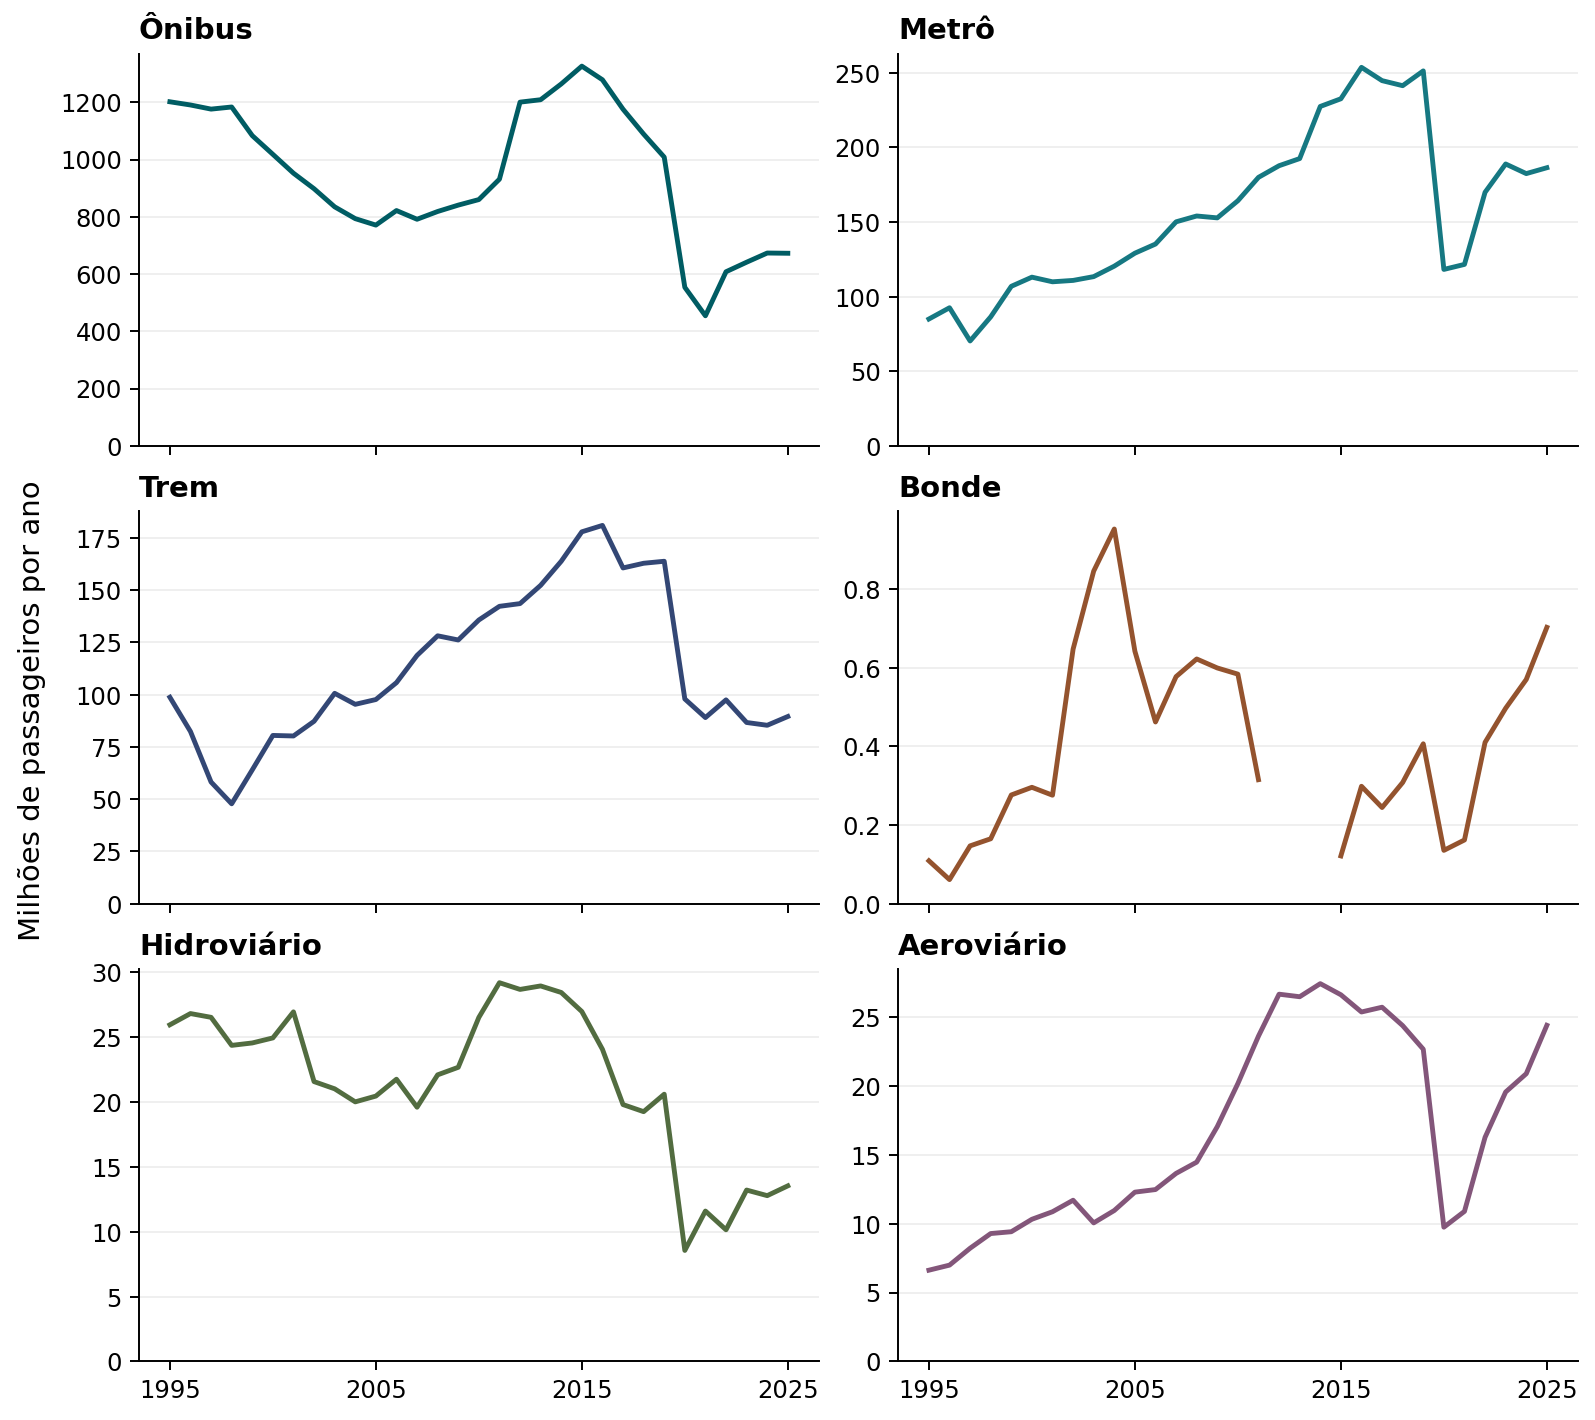

In [4]:
gerar(dados)
display(Image(filename=str(ASSETS / "series.png")))

## 4. Como mudou a participação dos modais entre 1995 e 2025?

O denominador exige os seis registros do ano. Uma ausência em qualquer modal impede calcular a composição completa daquele ano.

In [5]:
total = dados.sum(axis=1, min_count=len(MODAIS))
participacao = dados.div(total, axis=0).mul(100)
participacao.loc[[1995, 2019, 2025]].round(2)

,onibus,metro,trem,bonde,hidroviario,aeroviario
ano,,,,,,
1995,84.74,5.99,6.97,0.01,1.83,0.47
2019,68.73,17.12,11.17,0.03,1.40,1.54
2025,68.13,18.88,9.07,0.07,1.37,2.47


## 5. Quais modais superaram em 2025 o volume de 2019, após a queda de 2020?

O índice fixa o nível de cada modal em 100 em 2019. Valores acima de 100 indicam movimento superior ao daquele ano.

[Abrir imagem completa (retomada.png)](../docs/assets/retomada.png)

In [6]:
indice = dados.loc[[2019, 2020, 2025]].div(dados.loc[2019]).mul(100)
indice.round(1)

,onibus,metro,trem,bonde,hidroviario,aeroviario
ano,,,,,,
2019,100.0,100.0,100.0,100.0,100.0,100.0
2020,54.9,47.1,59.8,33.3,41.6,43.0
2025,66.7,74.2,54.7,172.8,65.7,107.7


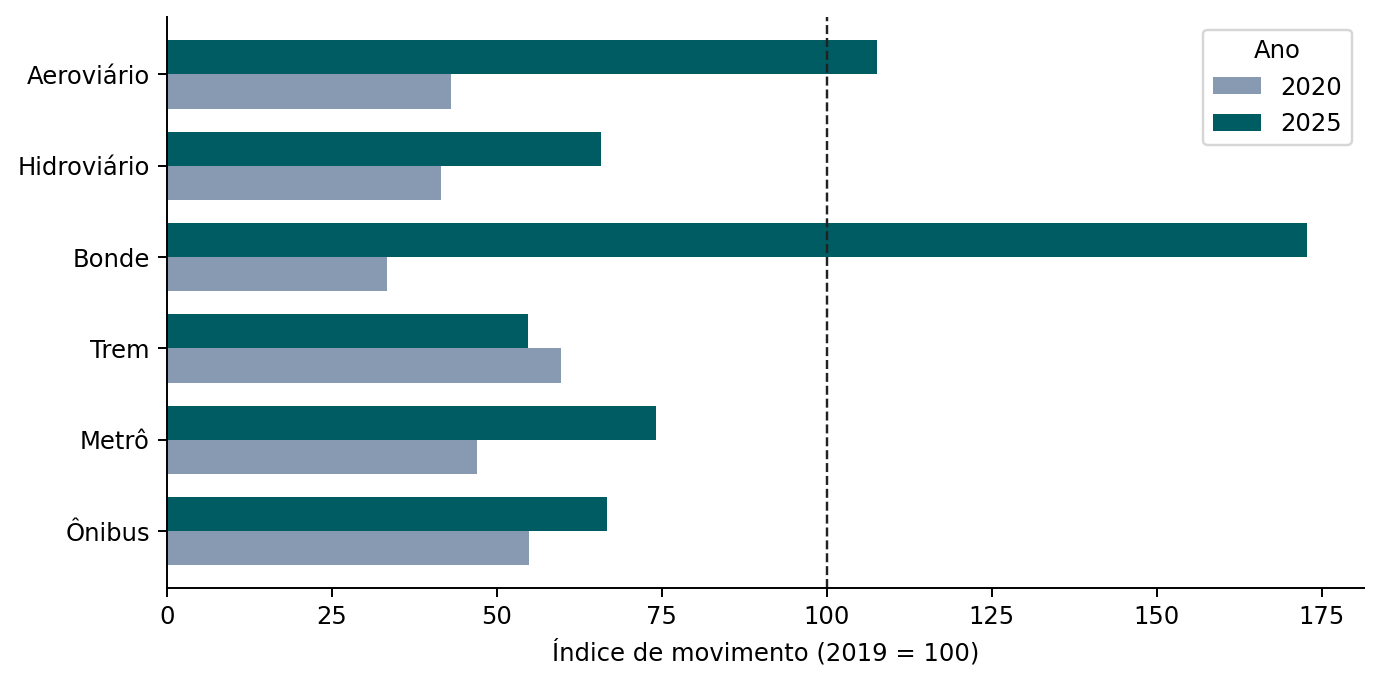

In [7]:
display(Image(filename=str(ASSETS / "retomada.png")))

## Conclusão

Em 2025, os ônibus ainda concentravam 68,1% do movimento. O bonde registrou o maior crescimento percentual frente a 2019 (+72,8%), mas representava apenas 0,07% do total em 2025. O aeroviário também superou 2019 (+7,7%). A tabela descreve volumes agregados e não acompanha as escolhas de um mesmo passageiro.

[Fonte primária · Data.Rio](https://www.data.rio/documents/5d5849bf28bf4f689214f890e3f4ac04/about)